# 01 · Auditoria de dados

> **Parte 1.1 do desafio:** qual o perfil geral dos dados? Distribuições, valores faltantes, outliers. Como você trataria cada caso?

## Resposta curta

- **A base é pequena e bem estruturada:** 500 campanhas de 2024, sem duplicatas, sem categorias inválidas. Mas tem **10 registros inconsistentes**, **7 colunas com faltantes** e **3 métricas que batem num limite**.
- **Os erros foram encontrados com as próprias contas do funil.** As métricas são redundantes entre si: CTR = cliques ÷ impressões, gasto = cliques × CPC, ROAS = receita ÷ gasto. Quando uma conta não fecha, as outras permitem **reconstruir** o valor. Em 5 dos 10 erros, duas contas independentes confirmam **qual** campo está errado. Nos outros 5, a escolha do campo se apoia em plausibilidade, porque a alternativa ficaria muito fora da faixa observada, e a correção fica marcada no log para revisão. Nenhuma linha foi descartada.
- **Dos faltantes, CPC e receita voltam exatos** pelas mesmas contas. Nas outras 5 colunas, nenhum teste encontrou relação entre a ausência e as variáveis observadas, o que é compatível com faltantes completamente aleatórios (MCAR). Essas colunas ficam vazias por enquanto, de propósito: a imputação acontece dentro do pipeline do modelo, na Parte 2, para não vazar informação do teste.
- **CTR travado em 15% e engajamento travado em 10% parecem tetos de registro, não erros.** Os valores ficam e ganham uma marcação.
- **Receita zero em Branding não é fracasso:** Branding não mede receita. Para essas campanhas, ROAS **não se aplica**.

Cada decisão está no código (`src/klike/data.py`), coberta por testes (`tests/test_data.py`), e cada correção fica registrada com a evidência em `reports/data_corrections.csv`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator, NullFormatter
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, permutation_test_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from klike import viz
from klike.config import (
    COLUMN_LABELS,
    CONTEXT_COLS,
    CREATIVE_COLS,
    PERFORMANCE_COLS,
    REPORTS_DIR,
    TARGET,
)
from klike.data import clean, load_raw

viz.set_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)

raw = load_raw()  # dados como vieram, com tipos corretos
result = clean(raw)  # dados corrigidos + log de auditoria
df = result.data

## 1. O que cada coluna representa, e quando ela existe

Antes de olhar qualquer número, separei as colunas pelo **momento em que a informação existe**. Essa divisão guia o resto do case.

| Grupo | Colunas | Quando existe | Papel no case |
| :-- | :-- | :-- | :-- |
| **Contexto** | plataforma, categoria, objetivo, faixa etária, retargeting | Antes da veiculação | Define o cenário. O que funciona depende dele. |
| **Criativo** | duração, formato, legenda, CTA, hook, rosto, densidade de texto, música/voz | Antes da veiculação | O que o time de criação controla. É aqui que as recomendações agem. |
| **Performance** | impressões, cliques, CTR, CPC, gasto, conversões, receita, ROAS, tempo assistido, engajamento | Só depois da veiculação | Mede o resultado. Não pode alimentar um modelo que precisa funcionar antes da veiculação. |
| **Alvo** | klike_score | | O que o modelo vai prever. |

**Por que isso importa:** um score que só pode ser calculado depois da veiculação não ajuda a decidir o que veicular. Um modelo que usa CTR para prever o score depende de algo que só existe depois do gasto. Essa separação volta na Parte 2, com dois modelos, e na Parte 3, em que o engine só recomenda mudar atributos do criativo.

In [2]:
group_of = {"campaign_id": "Identificação", "date": "Identificação", TARGET: "Alvo"}
group_of.update({c: "Contexto" for c in CONTEXT_COLS})
group_of.update({c: "Criativo" for c in CREATIVE_COLS})
group_of.update({c: "Performance" for c in PERFORMANCE_COLS})

profile = pd.DataFrame(
    {
        "grupo": [group_of[c] for c in raw.columns],
        "tipo": raw.dtypes.astype(str).values,
        "valores distintos": raw.nunique().values,
        "faltantes": raw.isna().sum().values,
    },
    index=raw.columns,
)
profile

,grupo,tipo,valores distintos,faltantes
campaign_id,Identificação,object,500,0
date,Identificação,datetime64[ns],273,0
platform,Contexto,category,3,0
category,Contexto,category,5,0
objective,Contexto,category,5,0
target_audience_age,Contexto,category,4,0
is_retargeting,Contexto,boolean,2,0
video_duration_s,Criativo,float64,56,39
format,Criativo,category,3,0
has_subtitle,Criativo,boolean,2,46


## 2. Perfil geral

In [3]:
print(f"Campanhas: {len(raw)} | Colunas: {raw.shape[1]}")
print(f"Período: {raw['date'].min():%d/%m/%Y} a {raw['date'].max():%d/%m/%Y}")
print(f"IDs duplicados: {raw['campaign_id'].duplicated().sum()}")
print(f"Linhas duplicadas (ignorando o ID): {raw.drop(columns='campaign_id').duplicated().sum()}")


def counts_line(col: str) -> str:
    counts = raw[col].value_counts(sort=False)
    return " · ".join(f"{k} {v}" for k, v in counts.items())


composition = pd.Series(
    {
        COLUMN_LABELS[c]: counts_line(c)
        for c in [
            "platform", "category", "objective", "target_audience_age", "format", "text_density"
        ]
    },
    name="campanhas por valor",
).to_frame()

binary = pd.DataFrame(
    {
        COLUMN_LABELS[c]: {
            "sim": int(raw[c].sum()),
            "não": int((~raw[c]).sum()),
            "faltante": int(raw[c].isna().sum()),
        }
        for c in ["has_hook", "has_face", "has_cta", "has_subtitle", "is_retargeting"]
    }
).T

display(composition, binary)

Campanhas: 500 | Colunas: 26
Período: 01/01/2024 a 30/12/2024
IDs duplicados: 0
Linhas duplicadas (ignorando o ID): 0


,campanhas por valor
Plataforma,Meta 241 · TikTok 176 · LinkedIn 83
Categoria,E-commerce 165 · SaaS 97 · Lead Gen 93 · App Install 82 · Branding 63
Objetivo,conversions 165 · traffic 150 · engagement 79 · awareness 60 · app_install 46
Faixa etária,18-24 137 · 25-34 143 · 35-44 139 · 45+ 81
Formato,vertical 269 · quadrado 120 · horizontal 111
Densidade de texto,low 179 · medium 230 · high 91


,sim,não,faltante
Hook nos 3 primeiros segundos,256,244,0
Rosto humano,269,231,0
Call-to-action,347,153,0
Legenda,263,191,46
Retargeting,117,383,0


**A amostra não é balanceada entre plataformas.** Meta tem quase metade das campanhas e LinkedIn só 83. Conclusões sobre LinkedIn vão ter intervalos de confiança mais largos, e o texto vai deixar isso explícito.

A estrutura entre as colunas de contexto importa mais do que as contagens:

In [4]:
display(
    pd.crosstab(raw["platform"], raw["format"]),
    pd.crosstab(raw["platform"], raw["target_audience_age"]),
    pd.crosstab(raw["category"], raw["objective"]),
)

format,vertical,quadrado,horizontal
platform,,,
Meta,106,68,67
TikTok,152,24,0
LinkedIn,11,28,44


target_audience_age,18-24,25-34,35-44,45+
platform,,,,
Meta,57,66,76,42
TikTok,78,54,30,14
LinkedIn,2,23,33,25


objective,conversions,traffic,engagement,awareness,app_install
category,,,,,
E-commerce,84,81,0,0,0
SaaS,37,33,0,27,0
Lead Gen,44,0,49,0,0
App Install,0,36,0,0,46
Branding,0,0,30,33,0


Três padrões estruturais que mudam a forma de analisar:

1. **Formato anda junto com plataforma.** O TikTok não tem nenhum vídeo horizontal e o LinkedIn tem só 11 verticais. Comparar "vertical vs. horizontal" no agregado mistura o efeito do formato com o efeito da plataforma.
2. **Faixa etária também.** O LinkedIn tem só 2 campanhas para 18-24, e o TikTok concentra o público jovem.
3. **O objetivo é quase determinado pela categoria.** Branding só roda awareness e engagement; App Install só app_install e traffic. Para o modelo, são variáveis em parte redundantes. Para a análise, os efeitos de uma e de outra são difíceis de separar.

**Decisão:** nas próximas etapas, os efeitos de atributos do criativo serão comparados **dentro de cada plataforma**, não no agregado.

## 3. Distribuições

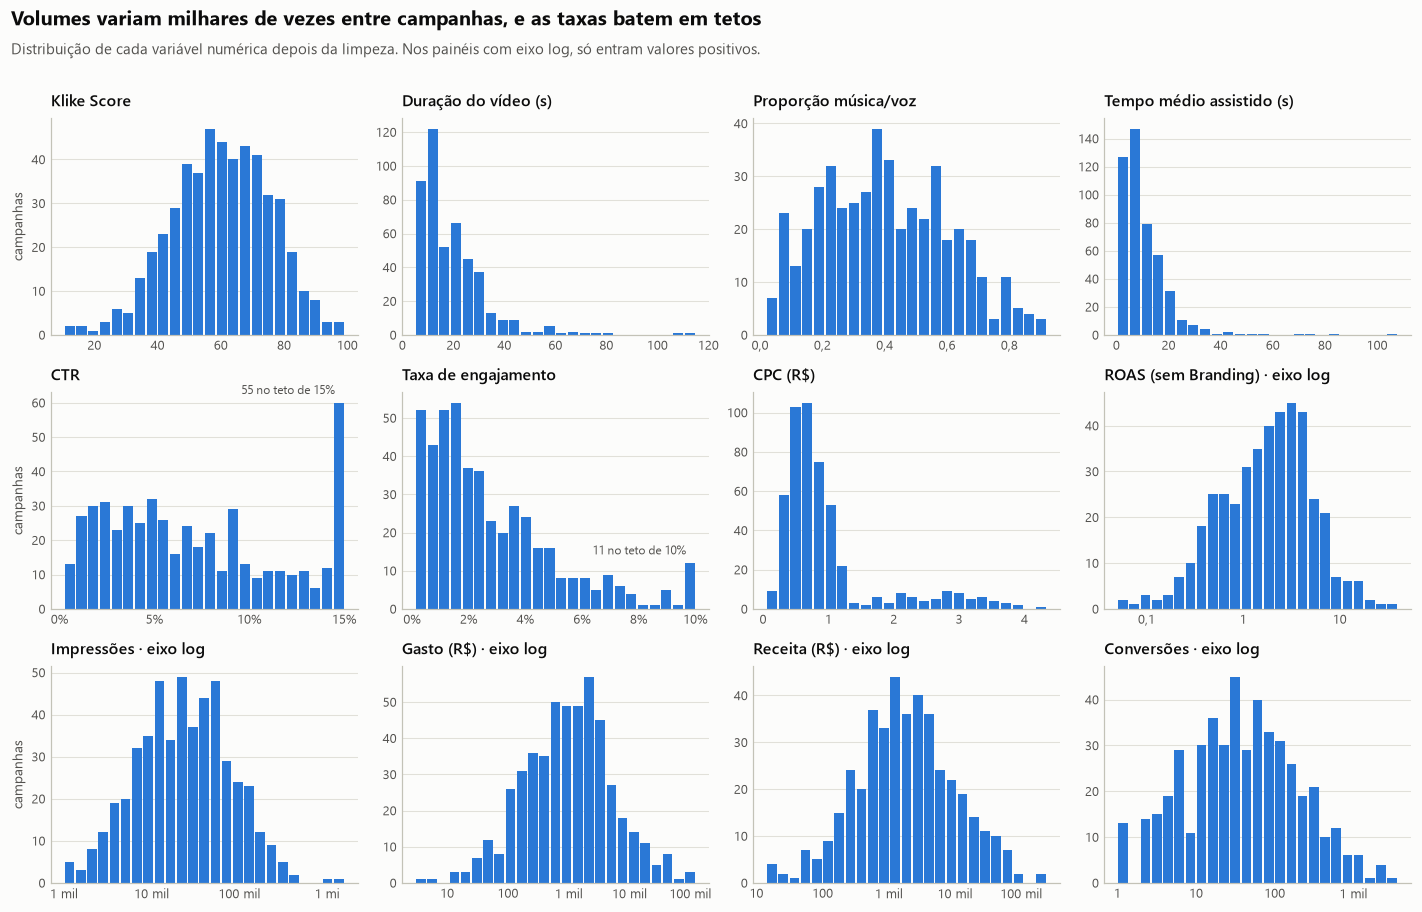

In [5]:
panels = [
    ("klike_score", False, None),
    ("video_duration_s", False, None),
    ("music_voice_ratio", False, None),
    ("avg_watch_time_s", False, None),
    ("ctr", False, None),
    ("engagement_rate", False, None),
    ("cpc", False, None),
    ("roas", True, df["flag_roas_applicable"]),
    ("impressions", True, None),
    ("spend", True, None),
    ("revenue", True, None),
    ("conversions", True, None),
]
formatters = {
    "ctr": viz.pct_formatter,
    "engagement_rate": viz.pct_formatter,
    "music_voice_ratio": viz.decimal_formatter(1),
}

fig, axes = plt.subplots(3, 4, figsize=(13, 8.4))
hist_counts = {}
for ax, (col, log_scale, mask) in zip(axes.flat, panels, strict=True):
    values = (df[col] if mask is None else df.loc[mask, col]).dropna()
    if log_scale:
        values = values[values > 0]
        bins = np.geomspace(values.min(), values.max(), 26)
        ax.set_xscale("log")
        ax.xaxis.set_major_formatter(viz.compact_formatter)
        ax.xaxis.set_minor_formatter(NullFormatter())
    else:
        bins = 24
        ax.xaxis.set_major_formatter(formatters.get(col, viz.compact_formatter))
    counts, edges, _ = ax.hist(values, bins=bins, color=viz.ACCENT, rwidth=0.86)
    hist_counts[col] = (counts, edges)
    title = COLUMN_LABELS[col] + (" · eixo log" if log_scale else "")
    if col == "roas":
        title = "ROAS (sem Branding) · eixo log"
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
for ax in axes[:, 0]:
    ax.set_ylabel("campanhas")


def note(ax, x, y, text, ha="right", dx=-6):
    ax.annotate(
        text,
        xy=(x, y),
        xytext=(dx, 4),
        textcoords="offset points",
        ha=ha,
        va="bottom",
        fontsize=8,
        color=viz.INK_SECONDARY,
    )


ax_of = {col: ax for ax, (col, _, _) in zip(axes.flat, panels, strict=True)}
ax_of["ctr"].xaxis.set_major_locator(MultipleLocator(0.05))
note(ax_of["ctr"], 0.15, hist_counts["ctr"][0][-1], "55 no teto de 15%")
note(ax_of["engagement_rate"], 0.10, hist_counts["engagement_rate"][0][-1], "11 no teto de 10%")

viz.add_header(
    fig,
    "Volumes variam milhares de vezes entre campanhas, e as taxas batem em tetos",
    "Distribuição de cada variável numérica depois da limpeza. Nos painéis com eixo log, "
    "só entram valores positivos.",
)
viz.save(fig, "01_distribuicoes")
plt.show()

O que a figura mostra:

- **O Klike Score é um alvo bem comportado.** Média de 60, desvio-padrão de 15,6, de 10 a 99, quase simétrico e sem acúmulo nos extremos. Dá para modelar direto, sem transformação.
- **Métricas de volume são de cauda longa.** Impressões, gasto, receita e conversões variam de 1.500 a 40.000 vezes entre a menor e a maior campanha. A média engana: nas análises uso mediana e escala log.
- **CTR e engajamento têm "paredes" no topo.** Não é uma distribuição que termina suavemente: há um acúmulo exatamente no limite. A seção 6 trata isso.
- **O CPC tem dois grupos:** a maioria abaixo de R$ 1,50 e um grupo entre R$ 1,50 e R$ 4,50. O segundo grupo é todo do LinkedIn, com mediana de R$ 2,63 contra R$ 0,82 na Meta e R$ 0,52 no TikTok.

## 4. Consistência: as contas do funil como checksum

Três identidades precisam fechar em toda campanha:

- **impressões = cliques ÷ CTR**
- **gasto = cliques × CPC**
- **ROAS = receita ÷ gasto**

Essa redundância é uma vantagem. Em vez de caçar outliers "no olho" ou por regra estatística genérica, testo se as contas fecham. Quando uma não fecha, as outras identidades ajudam a apontar **qual** campo está errado.

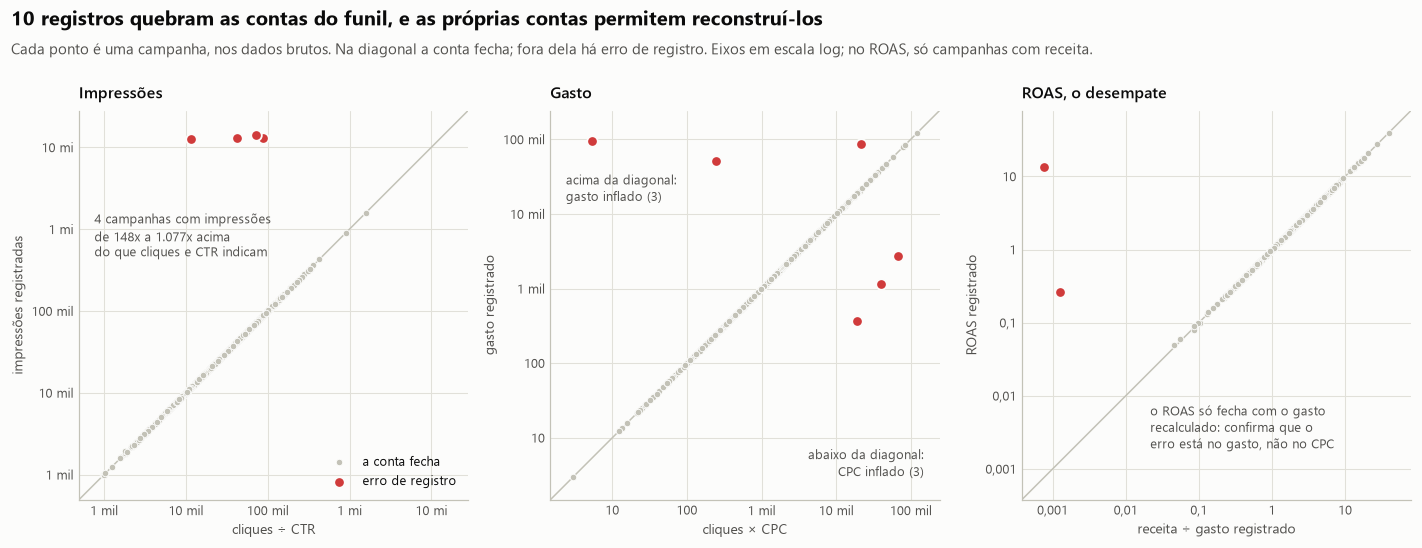

In [6]:
def ids_for(rule: str) -> set:
    return set(result.log.loc[result.log["rule"] == rule, "campaign_id"])


impressions_bad = raw["campaign_id"].isin(ids_for("Impressões infladas"))
spend_bad = raw["campaign_id"].isin(ids_for("Gasto fora de escala"))
cpc_bad = raw["campaign_id"].isin(ids_for("CPC fora de escala"))


def identity_panel(ax, x, y, bad, title, xlabel, ylabel):
    ok = x.notna() & y.notna() & (x > 0) & (y > 0)
    lo = min(x[ok].min(), y[ok].min()) / 2
    hi = max(x[ok].max(), y[ok].max()) * 2
    ax.plot([lo, hi], [lo, hi], color=viz.BASELINE, linewidth=1, zorder=1)
    ax.scatter(
        x[ok & ~bad], y[ok & ~bad], s=18, color=viz.CONTEXT,
        edgecolor=viz.SURFACE, linewidth=0.6, zorder=2, label="a conta fecha",
    )
    ax.scatter(
        x[ok & bad], y[ok & bad], s=48, color=viz.CRITICAL,
        edgecolor=viz.SURFACE, linewidth=1.2, zorder=3, label="erro de registro",
    )
    ax.set(xscale="log", yscale="log", xlim=(lo, hi), ylim=(lo, hi))
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(viz.compact_formatter)
        axis.set_minor_formatter(NullFormatter())


def side_note(ax, x, y, text, ha="left", va="top"):
    ax.text(x, y, text, transform=ax.transAxes, ha=ha, va=va, fontsize=8.5,
            color=viz.INK_SECONDARY, linespacing=1.35)


fig, axes = plt.subplots(1, 3, figsize=(13, 4.9))
identity_panel(
    axes[0], raw["clicks"] / raw["ctr"], raw["impressions"], impressions_bad,
    "Impressões", "cliques ÷ CTR", "impressões registradas",
)
side_note(
    axes[0], 0.04, 0.74,
    "4 campanhas com impressões\nde 148x a 1.077x acima\ndo que cliques e CTR indicam",
)
axes[0].legend(loc="lower right")

identity_panel(
    axes[1], raw["clicks"] * raw["cpc"], raw["spend"], spend_bad | cpc_bad,
    "Gasto", "cliques × CPC", "gasto registrado",
)
side_note(axes[1], 0.04, 0.84, "acima da diagonal:\ngasto inflado (3)")
side_note(axes[1], 0.96, 0.05, "abaixo da diagonal:\nCPC inflado (3)", ha="right", va="bottom")

identity_panel(
    axes[2], raw["revenue"] / raw["spend"], raw["roas"], spend_bad,
    "ROAS, o desempate", "receita ÷ gasto registrado", "ROAS registrado",
)
side_note(
    axes[2], 0.33, 0.12,
    "o ROAS só fecha com o gasto\nrecalculado: confirma que o\nerro está no gasto, não no CPC",
    va="bottom",
)

viz.add_header(
    fig,
    "10 registros quebram as contas do funil, e as próprias contas permitem reconstruí-los",
    "Cada ponto é uma campanha, nos dados brutos. Na diagonal a conta fecha; fora dela há erro "
    "de registro. Eixos em escala log; no ROAS, só campanhas com receita.",
)
viz.save(fig, "01_identidades_do_funil")
plt.show()

### Como decidir qual campo está errado

**Impressões (4 campanhas).** Nelas, cliques × CPC bate com o gasto, então os cliques estão confirmados por uma segunda conta. Sobram impressões e CTR como suspeitos, e nenhuma conta separa os dois: a escolha é por plausibilidade. Se o erro estivesse no CTR, o CTR verdadeiro seria de 0,003% a 0,03%, de 8 a 80 vezes abaixo do menor CTR da base, que é 0,22%. Já o CTR registrado, entre 1,5% e 4,3%, é plausível. O erro está nas impressões, infladas entre 148 e 1.077 vezes. Correção: **impressões = cliques ÷ CTR**.

**Gasto vs. CPC (6 campanhas).** Quando gasto ≠ cliques × CPC, qualquer um dos dois pode estar errado. O ROAS desempata, porque foi calculado com o gasto verdadeiro:

- Em **KLK-0100, KLK-0240 e KLK-0416**, receita ÷ gasto registrado reproduz o ROAS. O gasto está certo e o **CPC** está errado: R$ 20 a R$ 26 por clique, quando o maior CPC legítimo da Meta é R$ 1,37.
- Em **KLK-0109 e KLK-0259**, só receita ÷ (cliques × CPC) reproduz o ROAS. O **gasto** está errado, inflado 209 e 17.743 vezes.
- **KLK-0224** é Branding, com receita zero, então o ROAS não desempata. O CPC registrado, R$ 1,22, está dentro da faixa da Meta. O CPC implícito no gasto seria R$ 4,81, mais de 3 vezes o maior CPC da Meta na base. A versão plausível é a do CPC registrado, então o **gasto** é corrigido.

**Duas bases de decisão.** Nos 5 casos resolvidos pelo ROAS, duas contas independentes concordam sobre o campo errado: a base é a **identidade**. Nas 4 impressões e no KLK-0224, as contas mostram que há erro, mas nenhuma diz qual campo está errado: a base é a **plausibilidade**. Para não transformar suposição em correção, o código só corrige nesses casos quando uma versão cai dentro da faixa observada nas campanhas em que as contas fecham e a outra cai fora dela. Se as duas fossem plausíveis, o registro iria para revisão manual, sem correção. Aqui as alternativas ficam longe da faixa: de 8 a 80 vezes abaixo do menor CTR da base e 3,5 vezes acima do maior CPC da Meta.

O notebook 02 refaz a análise sem essas 5 campanhas: os principais efeitos ficam próximos, e só um nível de evidência muda, o do texto alto no ROAS, que passa de robusto a indício.

O log abaixo registra cada correção com a base da decisão e a evidência usada. As 5 por plausibilidade são as que eu conferiria com a fonte dos dados:

In [7]:
error_rules = ["Impressões infladas", "CPC fora de escala", "Gasto fora de escala"]
result.log.loc[
    result.log["rule"].isin(error_rules),
    ["campaign_id", "column", "old_value", "new_value", "basis", "evidence"],
]

,campaign_id,column,old_value,new_value,basis,evidence
0,KLK-0148,impressions,13007321.00,42500.00,plausibilidade,"impressões 306x acima de cliques/CTR; cliques confirmados por gasto = cliques x CPC; o CTR alternativo, cliques/impr..."
1,KLK-0232,impressions,12594257.00,11695.00,plausibilidade,"impressões 1.077x acima de cliques/CTR; cliques confirmados por gasto = cliques x CPC; o CTR alternativo, cliques/im..."
2,KLK-0258,impressions,12873562.00,86948.00,plausibilidade,"impressões 148x acima de cliques/CTR; cliques confirmados por gasto = cliques x CPC; o CTR alternativo, cliques/impr..."
3,KLK-0413,impressions,14052761.00,72059.00,plausibilidade,"impressões 195x acima de cliques/CTR; cliques confirmados por gasto = cliques x CPC; o CTR alternativo, cliques/impr..."
4,KLK-0100,cpc,20.00,0.39,identidade,"gasto confirmado pelo ROAS (receita/gasto = 3,13); CPC 20,00 não bate com gasto/cliques = 0,39"
5,KLK-0109,spend,50544.77,241.90,identidade,"cliques x CPC confirmado pelo ROAS (receita/(cliques x CPC) = 0,26); gasto registrado 209x maior"
6,KLK-0224,spend,85023.80,21557.40,plausibilidade,"ROAS não desempata (receita zero ou ausente); faixa de CPC da plataforma 0,21 a 1,37: CPC registrado 1,22 dentro, ga..."
7,KLK-0240,cpc,24.17,0.98,identidade,"gasto confirmado pelo ROAS (receita/gasto = 4,31); CPC 24,17 não bate com gasto/cliques = 0,98"
8,KLK-0259,spend,95811.69,5.40,identidade,"cliques x CPC confirmado pelo ROAS (receita/(cliques x CPC) = 13,45); gasto registrado 17.743x maior"
9,KLK-0416,cpc,26.05,0.74,identidade,"gasto confirmado pelo ROAS (receita/gasto = 2,21); CPC 26,05 não bate com gasto/cliques = 0,74"


**Por que corrigir em vez de remover?** Porque o resto da linha está certo: atributos do criativo, klike_score, conversões. Remover 10 campanhas jogaria fora informação boa por causa de um campo ruim.

**E por que não usar uma regra estatística de outliers?** Ela pegaria os CPCs absurdos, mas erraria no gasto, que tem cauda longa. A regra do intervalo interquartil sobre o gasto bruto marca 61 campanhas, 58 delas legítimas. Em escala log, os três gastos corrigidos nem chegam a ser marcados. As contas do funil isolam exatamente os 10 registros inconsistentes, sem marcar nenhuma campanha coerente.

## 5. Valores faltantes

Sete colunas têm valores ausentes. Esta seção responde três perguntas: quanto falta, **por que** falta e o que fazer com cada coluna.

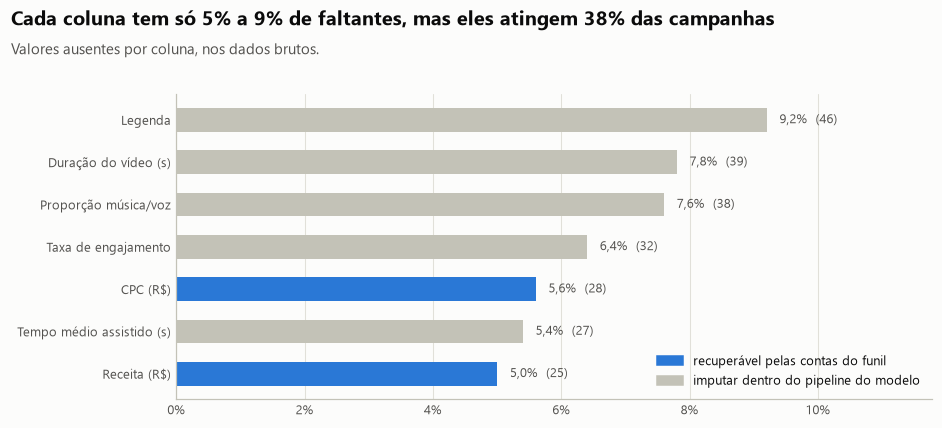

In [8]:
missing = raw.isna().sum().loc[lambda s: s > 0].sort_values()
share = missing / len(raw)
recoverable = {"cpc", "revenue"}

fig, ax = plt.subplots(figsize=(8.6, 4.0))
ax.barh(
    [COLUMN_LABELS[c] for c in missing.index],
    share.values,
    height=0.56,
    color=[viz.ACCENT if c in recoverable else viz.CONTEXT for c in missing.index],
)
for i, (n, s) in enumerate(zip(missing.values, share.values, strict=True)):
    ax.text(s + 0.002, i, f"{viz.fmt_pct(s, 1)}  ({n})", va="center", fontsize=8.5,
            color=viz.INK_SECONDARY)
ax.set_xlim(0, share.max() * 1.28)
ax.xaxis.set_major_formatter(viz.pct_formatter)
ax.grid(axis="y", visible=False)
ax.legend(
    handles=[
        Patch(color=viz.ACCENT, label="recuperável pelas contas do funil"),
        Patch(color=viz.CONTEXT, label="imputar dentro do pipeline do modelo"),
    ],
    loc="lower right",
)
viz.add_header(
    fig,
    "Cada coluna tem só 5% a 9% de faltantes, mas eles atingem 38% das campanhas",
    "Valores ausentes por coluna, nos dados brutos.",
)
viz.save(fig, "01_faltantes")
plt.show()

### 5.1 O que já foi tratado e o que fica para o pipeline

| Colunas | Situação | Onde acontece |
| :-- | :-- | :-- |
| CPC e receita | Recuperadas pelas contas do funil. CPC = gasto ÷ cliques é exato; receita = ROAS × gasto tem erro máximo de 0,5% do gasto | Na limpeza, já aplicada |
| Duração, legenda, música/voz, tempo assistido e engajamento | Mantidas vazias **de propósito** | No pipeline do modelo, na Parte 2 |

Por que não imputar essas cinco colunas agora:

1. **Evita vazamento de informação.** Imputar é aprender algo com os dados, como uma mediana. Feito na base inteira, antes de separar treino e teste, isso deixa as linhas de teste influenciarem o treino, e a avaliação do modelo sai otimista demais.
2. **Não distorce a análise exploratória.** Se os faltantes forem aleatórios, analisar só os valores observados é correto. Imputar criaria dados artificiais: 39 vídeos com exatamente a duração mediana formariam um pico falso e enfraqueceriam correlações reais.
3. **O melhor método depende do modelo.** A imputação precisa respeitar restrições do negócio e o que o modelo pré-veiculação pode usar, e isso se decide junto com o modelo.
4. **O mesmo tratamento vale em produção.** O engine vai receber campanhas novas com campos vazios. Com a imputação dentro do pipeline, exatamente o mesmo passo roda no treino e na hora de recomendar.

O notebook 02 confirma isso na prática: refazendo as estimativas principais com imputação pela mediana, ou só com as campanhas completas, as conclusões não mudam, e a imputação pela mediana cria vídeos assistidos por mais tempo do que duram.

**E por que não descartar as linhas incompletas?** A conta abaixo mostra que, mesmo depois de recuperar CPC e receita, 30% das campanhas ainda têm algum faltante. Descartá-las jogaria fora quase um terço da base por um problema que atinge menos de 10% de cada coluna.

In [9]:
any_missing = raw[missing.index].isna().any(axis=1)
expected = len(raw) * (1 - np.prod(1 - raw[missing.index].isna().mean()))
still_missing = df[missing.index].isna().any(axis=1)
print(f"Campanhas com pelo menos 1 faltante: {any_missing.sum()} ({any_missing.mean():.0%})")
print(f"Esperado se cada coluna perdesse valores de forma independente: {expected:.0f}")
print(
    f"Depois de recuperar CPC e receita: {still_missing.sum()} campanhas "
    f"({still_missing.mean():.0%}) ainda têm algum faltante"
)

Campanhas com pelo menos 1 faltante: 191 (38%)
Esperado se cada coluna perdesse valores de forma independente: 193
Depois de recuperar CPC e receita: 152 campanhas (30%) ainda têm algum faltante


Imputar, porém, só é seguro se a ausência for aleatória. É isso que as próximas subseções verificam.

### 5.2 MCAR, MAR e MNAR: por que um valor está faltando

Esses três termos não são tratamentos. São **diagnósticos do mecanismo** que gerou a ausência, e o tratamento certo depende deles.

| Mecanismo | A ausência depende de | Como seria neste dataset | Tratamento adequado |
| :-- | :-- | :-- | :-- |
| **MCAR**: completamente aleatório | Nada | Uma falha aleatória na exportação dos dados | Descartar não cria viés, só desperdiça dados; imputar também é seguro |
| **MAR**: aleatório dado o que se observa | Outras colunas observadas | A duração falta mais no LinkedIn | Imputar usando as colunas que explicam a ausência |
| **MNAR**: não aleatório | O próprio valor que falta | Vídeos longos ficam sem a duração registrada | Nenhum método resolve só com os dados; a análise de sensibilidade mostra o quanto a conclusão depende disso |

Com os dados, dá para testar se a ausência se relaciona com alguma coluna observada, ou seja, MCAR contra MAR. MNAR não pode ser provado só com os dados, porque o valor que decidiria a questão é justamente o que falta. Mas dá para buscar evidência indireta, como na seção 5.4.

### 5.3 Teste de MAR: a ausência se relaciona com alguma coluna observada?

Duas verificações complementares, para cada coluna com faltante:

1. **Testes um a um.** A ausência é comparada com cada uma das outras 24 variáveis, incluindo o mês: Mann-Whitney para as numéricas e qui-quadrado para as categóricas. Com tantos testes, alguns p-valores baixos aparecem por puro acaso. Por isso aplico a correção de Benjamini-Hochberg para múltiplas comparações.
2. **Um modelo que tenta prever a ausência.** Uma regressão logística recebe todas as outras colunas ao mesmo tempo e tenta adivinhar quais linhas têm o valor faltante. Isso pega relações que os testes um a um não veem, como combinações de variáveis. Se o modelo não acerta mais que o acaso, medido pela AUC com validação cruzada e por um teste de permutação, não há sinal de que a ausência dependa do que é observado.

In [10]:
numeric_cols = [
    "video_duration_s", "music_voice_ratio", "impressions", "clicks", "ctr", "cpc", "spend",
    "conversions", "revenue", "roas", "avg_watch_time_s", "engagement_rate", TARGET,
]
categorical_cols = [
    "platform", "category", "objective", "target_audience_age", "format", "text_density",
    "is_retargeting", "has_subtitle", "has_cta", "has_hook", "has_face", "month",
]
heavy_tailed = ["impressions", "clicks", "spend", "conversions", "revenue"]
observed = df.assign(month=df["date"].dt.month.astype(str))


def univariate_pvalues(missing_col: str) -> pd.Series:
    """p-valor da associação entre 'está faltando' e cada outra variável."""
    is_missing = raw[missing_col].isna()
    pvalues = {}
    for var in numeric_cols:
        if var != missing_col:
            ok = observed[var].notna()
            pvalues[var] = stats.mannwhitneyu(
                observed.loc[ok & is_missing, var], observed.loc[ok & ~is_missing, var]
            ).pvalue
    for var in categorical_cols:
        if var != missing_col:
            values = observed[var].astype("object")
            ok = values.notna()
            pvalues[var] = stats.chi2_contingency(pd.crosstab(is_missing[ok], values[ok]))[1]
    return pd.Series(pvalues)


def missingness_auc(missing_col: str, n_permutations: int = 100) -> tuple[float, float, float]:
    """AUC de um modelo que tenta prever a ausência, o limite do acaso e o p-valor.

    O pré-processamento (mediana, log e padronização) não usa o rótulo "está faltando".
    Por isso pode ser ajustado uma vez só, fora da validação cruzada, sem criar sinal
    artificial. Isso deixa rápidos os milhares de reajustes do teste de permutação.
    """
    y = raw[missing_col].isna().astype(int).to_numpy()
    num = [c for c in numeric_cols if c != missing_col]
    cat = [c for c in categorical_cols if c != missing_col]
    X = observed[num + cat].copy()
    for c in cat:
        X[c] = X[c].astype("object").where(X[c].notna(), "NA").astype(str)
    heavy = [c for c in num if c in heavy_tailed]
    light = [c for c in num if c not in heavy_tailed]
    preprocess = ColumnTransformer(
        [
            ("heavy", make_pipeline(SimpleImputer(strategy="median"),
                                    FunctionTransformer(np.log1p), StandardScaler()), heavy),
            ("light", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), light),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
        ]
    )
    X_ready = preprocess.fit_transform(X)
    model = LogisticRegression(C=0.3, class_weight="balanced", solver="liblinear")
    auc, permuted_aucs, p_value = permutation_test_score(
        model, X_ready, y, scoring="roc_auc",
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0),
        n_permutations=n_permutations, random_state=0,
    )
    return auc, np.quantile(permuted_aucs, 0.975), p_value


pvalues = pd.concat({col: univariate_pvalues(col) for col in missing.index})
qvalues = pd.Series(stats.false_discovery_control(pvalues.values, method="bh"), index=pvalues.index)

rows = []
for col in missing.index:
    auc, chance_limit, p_perm = missingness_auc(col)
    rows.append(
        {
            "coluna": COLUMN_LABELS[col],
            "faltantes": int(raw[col].isna().sum()),
            "testes com p < 0,05": f"{(pvalues[col] < 0.05).sum()} de {len(pvalues[col])}",
            "menor p-valor": pvalues[col].min(),
            "menor p corrigido": qvalues[col].min(),
            "AUC do modelo": auc,
            "limite do acaso": chance_limit,
            "p da permutação": p_perm,
        }
    )
display(
    pd.DataFrame(rows).round(
        {
            "menor p-valor": 3,
            "menor p corrigido": 2,
            "AUC do modelo": 2,
            "limite do acaso": 2,
            "p da permutação": 2,
        }
    )
)
print(
    f"{len(pvalues)} testes no total | p < 0,05: {(pvalues < 0.05).sum()} "
    f"(esperado só por acaso: {len(pvalues) * 0.05:.0f}) | "
    f"significativos após a correção: {(qvalues < 0.05).sum()}"
)

,coluna,faltantes,"testes com p < 0,05",menor p-valor,menor p corrigido,AUC do modelo,limite do acaso,p da permutação
0,Receita (R$),25,1 de 24,0.024,0.74,0.56,0.63,0.27
1,Tempo médio assistido (s),27,4 de 24,0.002,0.40,0.57,0.65,0.25
2,CPC (R$),28,1 de 24,0.049,0.74,0.56,0.62,0.24
3,Taxa de engajamento,32,0 de 24,0.065,0.74,0.52,0.62,0.41
4,Proporção música/voz,38,1 de 24,0.035,0.74,0.54,0.61,0.23
5,Duração do vídeo (s),39,0 de 24,0.222,0.82,0.41,0.62,0.86
6,Legenda,46,1 de 24,0.027,0.74,0.55,0.64,0.27


168 testes no total | p < 0,05: 8 (esperado só por acaso: 8) | significativos após a correção: 0


Como ler a tabela: a AUC mede o quanto o modelo acerta quais linhas têm faltante. AUC de 0,5 é chute. O "limite do acaso" é a maior AUC que o modelo costuma atingir quando os rótulos são embaralhados de propósito, ou seja, quando não há nada para aprender.

- **Testes um a um.** 8 dos 168 testes têm p < 0,05, praticamente o que o acaso produziria. Depois da correção, nenhum é significativo. O único padrão que chama atenção é o tempo assistido, que concentra metade dos p-valores baixos, três deles ligados ao volume da campanha. Mas nenhum resiste à correção, e o modelo não consegue prever essa ausência.
- **Modelo.** Todas as AUCs ficam abaixo do limite do acaso, e nenhum teste de permutação é significativo. As outras colunas não ajudam a prever onde estão os faltantes.
- **Sobreposição.** Como mostrado em 5.1, 191 campanhas têm algum faltante, contra 193 esperadas se cada coluna perdesse valores de forma independente. Os faltantes não se concentram nas mesmas linhas.

**Conclusão: nenhum sinal de MAR.**

### 5.4 Teste de MNAR: evidência indireta

Se vídeos longos perdessem a duração com mais frequência, não daria para ver isso olhando a duração, porque ela é justamente o que falta. Mas dá para olhar uma variável observada que anda junto com ela. Se a ausência dependesse da duração, essa variável seria diferente entre as campanhas com e sem duração.

Primeiro, qual é a variável mais correlacionada com cada coluna numérica que tem faltante?

In [11]:
def strongest_partner(col: str) -> tuple[str, float]:
    """Variável numérica com a maior correlação de Spearman, em módulo, com a coluna."""
    rhos = {}
    for var in numeric_cols:
        if var != col:
            ok = df[col].notna() & df[var].notna()
            rhos[var] = stats.spearmanr(df.loc[ok, col], df.loc[ok, var])[0]
    best = max(rhos, key=lambda k: abs(rhos[k]))
    return best, rhos[best]


partners = pd.DataFrame(
    [
        {
            "coluna com faltante": COLUMN_LABELS[col],
            "variável mais correlacionada": COLUMN_LABELS[strongest_partner(col)[0]],
            "correlação": strongest_partner(col)[1],
        }
        for col in ["video_duration_s", "avg_watch_time_s", "engagement_rate", "music_voice_ratio"]
    ]
).round(2)
display(partners)


def shadow_check(missing_col: str, partner_col: str) -> dict:
    """Compara a variável parceira entre linhas com e sem o valor faltante."""
    is_missing = raw[missing_col].isna()
    with_gap = df.loc[is_missing, partner_col].dropna()
    without_gap = df.loc[~is_missing, partner_col].dropna()
    return {
        "coluna com faltante": COLUMN_LABELS[missing_col],
        "comparada por": COLUMN_LABELS[partner_col],
        "mediana onde falta": with_gap.median(),
        "mediana onde não falta": without_gap.median(),
        "p-valor": stats.mannwhitneyu(with_gap, without_gap).pvalue,
    }


display(
    pd.DataFrame(
        [
            shadow_check("video_duration_s", "avg_watch_time_s"),
            shadow_check("avg_watch_time_s", "video_duration_s"),
        ]
    ).round(2)
)

,coluna com faltante,variável mais correlacionada,correlação
0,Duração do vídeo (s),Tempo médio assistido (s),0.76
1,Tempo médio assistido (s),Duração do vídeo (s),0.76
2,Taxa de engajamento,Klike Score,0.29
3,Proporção música/voz,Klike Score,-0.08


,coluna com faltante,comparada por,mediana onde falta,mediana onde não falta,p-valor
0,Duração do vídeo (s),Tempo médio assistido (s),6.6,7.8,0.50
1,Tempo médio assistido (s),Duração do vídeo (s),16.0,16.0,0.97


A legenda é uma coluna sim/não, então o teste é outro. Campanhas com legenda têm score médio mais alto. Se as campanhas sem marcação fossem, na verdade, todas sem legenda, o score delas ficaria perto do score das campanhas sem legenda. Se forem uma mistura igual à do resto da base, como em MCAR, o score fica no meio.

In [12]:
subtitle = df["has_subtitle"]
with_subtitle = subtitle.fillna(False).astype(bool)
without_subtitle = (~subtitle).fillna(False).astype(bool)
unknown = subtitle.isna()

score_with = df.loc[with_subtitle, TARGET].mean()
score_without = df.loc[without_subtitle, TARGET].mean()
share_with = with_subtitle.sum() / subtitle.notna().sum()
unknown_scores = df.loc[unknown, TARGET]

display(
    pd.DataFrame(
        {
            "score médio": [
                share_with * score_with + (1 - share_with) * score_without,
                score_without,
                score_with,
                unknown_scores.mean(),
            ]
        },
        index=[
            "esperado se a mistura for igual à da base (MCAR)",
            "esperado se todas fossem sem legenda",
            "esperado se todas tivessem legenda",
            f"observado nas {unknown.sum()} campanhas sem marcação",
        ],
    ).round(1)
)
print(
    f"Erro-padrão do score observado: {viz.fmt_number(unknown_scores.sem(), 1)} | "
    f"campanhas com legenda na base: {share_with:.0%}"
)

,score médio
esperado se a mistura for igual à da base (MCAR),60.2
esperado se todas fossem sem legenda,56.0
esperado se todas tivessem legenda,63.2
observado nas 46 campanhas sem marcação,60.1


Erro-padrão do score observado: 2,6 | campanhas com legenda na base: 58%


- **Duração e tempo assistido** têm correlação de 0,76 entre si, então um serve de pista para o outro. As campanhas sem duração têm tempo assistido parecido com o das demais, e as campanhas sem tempo assistido têm a mesma duração mediana. Não há sinal de que vídeos longos, ou curtos, percam esses valores com mais frequência.
- **Legenda.** O score das campanhas sem marcação, 60,1, é quase idêntico ao esperado se elas tivessem a mesma proporção de legenda do resto da base, 60,2. Se a ausência viesse de vídeos sem legenda, o esperado seria 56,0. Com 46 campanhas, a precisão é limitada, mas o resultado é compatível com MCAR.
- **Engajamento e música/voz** não têm nenhuma variável observada forte o bastante para servir de pista: as maiores correlações, em módulo, são 0,29 e 0,08. **Para essas duas colunas, MNAR não pode ser verificado.**

### 5.5 Conclusão e decisões

> Nenhum teste é significativo depois da correção para múltiplas comparações, e nenhum modelo consegue prever quais linhas têm faltante. Os dados são compatíveis com MCAR. MNAR não pode ser descartado só com os dados, mas onde existe uma variável correlacionada para checar, não aparece sinal.

Um limite honesto: com 25 a 46 faltantes por coluna, esses testes detectam relações moderadas ou fortes. Uma dependência fraca poderia passar despercebida, mas, justamente por ser fraca, teria pouco efeito no modelo.

Decisões para o pipeline da Parte 2:

- **Imputador ajustado só no treino**, dentro do pipeline, para não vazar informação do teste.
- **Indicador de ausência** para cada coluna imputada. Ele deixa o modelo usar a própria ausência como informação, sem confundi-la com o valor imputado. Se houver algum MNAR invisível, como pode acontecer em engajamento e música/voz, isso ajuda a prever, mas não elimina o viés: o valor que falta continua desconhecido.
- **Duração e tempo assistido imputados um a partir do outro.** Com correlação de 0,76, isso tende a ser mais preciso que a mediana, e a Parte 2 mede essa diferença. A imputação respeita a restrição **duração ≥ tempo assistido**, que a conta abaixo mostra ser necessária.
- **Uma questão em aberto.** O tempo assistido só existe depois da veiculação. Usá-lo para imputar a duração leva um pouco de informação do futuro para o modelo pré-veiculação. Em produção, a duração é sempre conhecida, porque vem do arquivo do vídeo, então o efeito tende a ser pequeno. Vou comparar as duas versões na Parte 2.
- **Legenda faltante no engine.** Em produto, um atributo sem marcação significa que o criativo não foi analisado. O engine da Parte 3 vai tratar "legenda desconhecida" como algo a verificar, sem supor que o vídeo não tem legenda.

In [13]:
no_duration = raw["video_duration_s"].isna()
watch_known = raw.loc[no_duration, "avg_watch_time_s"].dropna()
print(f"Campanhas sem duração: {no_duration.sum()}, com tempo assistido: {len(watch_known)}")
print(f"Maior tempo assistido entre elas: {watch_known.max():.0f} s")
print(f"Mediana da duração na base: {raw['video_duration_s'].median():.0f} s")

Campanhas sem duração: 39, com tempo assistido: 36
Maior tempo assistido entre elas: 84 s
Mediana da duração na base: 16 s


Em 36 das 39 campanhas sem duração, o tempo assistido existe e chega a 84 s. Imputar a mediana da duração, de 16 s, criaria vídeos assistidos por mais tempo do que duram.

## 6. Outliers, tetos e pisos

"Outlier" junta coisas que pedem tratamentos diferentes. Separei em cinco tipos.

In [14]:
next_below_cap = df.loc[df["ctr"] < 0.15, "ctr"].max()
limits = pd.DataFrame(
    [
        ["Possível teto", "CTR exatamente 15%", int(df["flag_ctr_at_cap"].sum())],
        ["Possível teto", "Engajamento exatamente 10%", int(df["flag_engagement_at_cap"].sum())],
        ["Limite", "Tempo assistido = duração do vídeo", int(df["flag_full_watch"].sum())],
        ["Piso", "Impressões exatamente 1.000", int((df["impressions"] == 1000).sum())],
        ["Piso", "Duração exatamente 5 s", int((df["video_duration_s"] == 5).sum())],
    ],
    columns=["tipo", "situação", "campanhas"],
)
display(limits)
print(
    f"Maior CTR abaixo do teto: {viz.fmt_number(next_below_cap, 4)}, "
    f"contra {int(df['flag_ctr_at_cap'].sum())} campanhas exatamente em 0,1500"
)

,tipo,situação,campanhas
0,Possível teto,CTR exatamente 15%,55
1,Possível teto,Engajamento exatamente 10%,11
2,Limite,Tempo assistido = duração do vídeo,32
3,Piso,Impressões exatamente 1.000,3
4,Piso,Duração exatamente 5 s,21


Maior CTR abaixo do teto: 0,1489, contra 55 campanhas exatamente em 0,1500


In [15]:
extremes = df.loc[
    df["campaign_id"].isin(["KLK-0435", "KLK-0008"]),
    ["campaign_id", "platform", "impressions", "clicks", "ctr", "cpc", "spend", "revenue", "roas"],
]
extremes

,campaign_id,platform,impressions,clicks,ctr,cpc,spend,revenue,roas
7,KLK-0008,LinkedIn,22617,1130,0.0500,0.05,56.5,2255.20,39.92
434,KLK-0435,Meta,1570242,72545,0.0462,1.16,84152.2,241597.29,2.87


| Tipo | O que é | Casos | Tratamento |
| :-- | :-- | :-- | :-- |
| **Erro de registro** | O valor quebra uma conta do funil | 10 | Corrigido pela própria conta, como na seção 4 |
| **Possível teto de registro** | Muitos valores exatamente no limite, e nenhum acima: CTR 15% e engajamento 10% | 55 e 11 | Mantido, com flag. O padrão sugere censura: o valor real pode ter sido maior. Se for, as diferenças entre as campanhas no teto ficam escondidas, e as estimativas sobre essas métricas podem ficar distorcidas |
| **Limite da métrica** | Tempo médio assistido igual à duração do vídeo | 32 | Mantido, com flag. Implausível como comportamento real, como explicado abaixo |
| **Piso** | Impressões = 1.000, duração = 5 s | 3 e 21 | Mantido. São valores plausíveis |
| **Extremo legítimo** | Valor raro, mas em que todas as contas fecham | ex.: KLK-0435 | Mantido. Análises usam mediana e escala log |

Dois casos merecem comentário:

- **KLK-0435** tem 1,57 milhão de impressões, 32 vezes a média. Mas CTR, gasto e ROAS fecham: é só uma campanha grande. Cortar esse ponto apagaria a campanha de maior receita da base.
- **KLK-0008** tem CPC de R$ 0,05 no LinkedIn, onde a mediana é R$ 2,63, e o maior ROAS da base, 39,9. As contas fecham, então não há prova de erro, e o registro fica. Mas é o tipo de caso que eu levaria ao time de dados antes de usar em um relatório para cliente. Como as análises de ROAS usam mediana, um ponto não muda as conclusões.

Sobre o tempo assistido igual à duração: na vida real, um tempo **médio** igual à duração exigiria que todo mundo assistisse ao vídeo inteiro. Isso provavelmente indica um limite da métrica, e não comportamento real. Na Parte 2, a taxa de conclusão (tempo assistido ÷ duração) fica limitada a 100%.

## 7. Zeros estruturais: Branding não mede receita

In [16]:
by_category = (
    df.groupby("category", observed=True)
    .agg(
        campanhas=("campaign_id", "size"),
        com_conversoes=("conversions", lambda s: int((s > 0).sum())),
        receita_zero=("revenue", lambda s: int((s == 0).sum())),
        roas_mediano=("roas", "median"),
    )
    .rename(
        columns={
            "com_conversoes": "com conversões",
            "receita_zero": "com receita zero",
            "roas_mediano": "ROAS mediano",
        }
    )
)
by_category

,campanhas,com conversões,com receita zero,ROAS mediano
category,,,,
E-commerce,165,163,2,1.87
SaaS,97,90,7,3.27
Lead Gen,93,90,3,2.25
App Install,82,81,1,0.48
Branding,63,57,63,0.00


Todas as 63 campanhas de Branding têm receita zero, embora 57 delas tenham conversões. Ou seja, em Branding as conversões não têm valor monetário associado. Nas outras categorias, as 13 campanhas com receita zero são justamente as que tiveram zero conversões, ou seja, são zeros legítimos.

**Decisão:** ROAS **não se aplica** a Branding (`flag_roas_applicable = False`). Tratar esse zero como "ROAS ruim" puxaria para baixo qualquer análise de ROAS por categoria, objetivo ou atributo criativo, só porque campanhas de awareness entraram na conta.

## 8. Resultado da limpeza

In [17]:
display(result.summary())

key_metrics = ["impressions", "cpc", "spend"]
before_after = pd.DataFrame(
    {
        "média antes": raw[key_metrics].mean(),
        "média depois": df[key_metrics].mean(),
        "máximo antes": raw[key_metrics].max(),
        "máximo depois": df[key_metrics].max(),
    }
).round(2)
display(before_after)

log_path = REPORTS_DIR / "data_corrections.csv"
result.log.to_csv(log_path, index=False)
print(
    f"Log com {len(result.log)} correções salvo em "
    f"{log_path.relative_to(REPORTS_DIR.parent).as_posix()}"
)
print(f"Pendências para revisão manual: {len(result.unresolved)}")

,rule,basis,registros,colunas
0,Impressões infladas,plausibilidade,4,impressions
1,CPC fora de escala,identidade,3,cpc
2,Gasto fora de escala,identidade,2,spend
3,Gasto fora de escala,plausibilidade,1,spend
4,CPC faltante recuperado,identidade,28,cpc
5,Receita faltante recuperada,identidade,25,revenue


,média antes,média depois,máximo antes,máximo depois
impressions,153738.52,49109.13,14052761.00,1570242.00
cpc,1.11,0.98,26.05,4.34
spend,4213.15,3794.00,121226.10,121226.10


Log com 63 correções salvo em reports/data_corrections.csv
Pendências para revisão manual: 0


**Quatro linhas, 0,8% da base, triplicavam a média de impressões** (de 49 mil para 154 mil), e os três gastos corrigidos inflavam o gasto total em R$ 210 mil, cerca de 11%. Qualquer análise de CPM, custo por conversão ou ROAS agregado teria saído distorcida.

## 9. Resumo das decisões e o que muda nas próximas etapas

| Situação | Casos | Decisão | Por quê |
| :-- | :-- | :-- | :-- |
| Impressões infladas | 4 | Recalcular: cliques ÷ CTR | Cliques confirmados pelo gasto; o CTR alternativo seria implausível (plausibilidade) |
| CPC fora de escala | 3 | Recalcular: gasto ÷ cliques | O ROAS confirma o gasto (identidade) |
| Gasto fora de escala | 3 | Recalcular: cliques × CPC | O ROAS confirma cliques × CPC em 2 (identidade); no KLK-0224, sem receita, só o CPC registrado é plausível (plausibilidade) |
| CPC faltante | 28 | Recuperar: gasto ÷ cliques | Conta exata |
| Receita faltante | 25 | Recuperar: ROAS × gasto | Conta com erro máximo de 0,5% do gasto |
| Faltantes em 5 colunas | 27 a 46 por coluna | Imputar no pipeline do modelo da Parte 2, com indicador de ausência | Compatível com MCAR: nenhum teste encontrou relação entre a ausência e as variáveis observadas; descartar perderia 30% da base |
| Possíveis tetos de CTR e engajamento | 55 e 11 | Manter, com flag | O acúmulo exato no limite sugere teto de registro; não é erro |
| Tempo assistido igual à duração | 32 | Manter, com flag | Média igual à duração é implausível; tratada como limite da métrica |
| Receita zero em Branding | 63 | ROAS "não se aplica" | Branding não mede receita |
| Extremos coerentes | ex.: KLK-0435 | Manter; usar mediana e log | As contas fecham; é variação real |

**Implicações para as Partes 1.2 a 3:**

1. **Separar o efeito do criativo do efeito da plataforma**, porque formato e faixa etária andam juntos com plataforma. Todo efeito é estimado com a plataforma como controle, e o formato é analisado dentro de cada plataforma.
2. **Usar mediana e escala log** para métricas de volume.
3. **Analisar ROAS só fora de Branding.**
4. **Imputar só dentro do pipeline de modelagem**, nunca antes de separar treino e teste.
5. **Modelar o Klike Score diretamente:** a distribuição é bem comportada e não pede transformação.